# Reinforcement Learning for Battery Energy Arbitrage in Power Markets

## Overview

This project trains reinforcement learning agents to operate a battery in a wholesale electricity market. The agent decides when to charge the battery (buy energy) and when to discharge it (sell energy) in order to profit from fluctuations in the electricity price, a strategy known as energy arbitrage. This sits at the intersection of power systems and quantitative trading, and it is an economically significant application as grid-scale storage grows.

The project is built in two stages, which together tell an honest story about when reinforcement learning helps:

1. **Tabular Q-learning from scratch**, implementing the Bellman update and an epsilon-greedy policy in NumPy. This agent learns genuine arbitrage behavior and is benchmarked against a random policy and a tuned rule-based heuristic.
2. **A Deep Q-Network (DQN)** in Keras, which replaces the discretized state of the tabular method with a continuous state and a neural network, together with experience replay and a target network. This agent captures structure that the tabular method discretizes away.

Every result is evaluated out-of-sample: the agents are trained on an earlier portion of the data and tested on a later, unseen portion, with no look-ahead. The reported figures are profits on the held-out test period.

## A note on the data

The price signal is constructed from real electricity demand data. The dataset is the PJM hourly demand series, a genuine record of electricity consumption in a large United States grid region, which carries authentic daily, weekly, and seasonal cycles. Wholesale electricity prices are primarily driven by demand, so the price is derived from the real demand through a transparent and documented model: price rises convexly with demand, reflecting the higher marginal cost of generation at peak load. The demand patterns the agent learns from are therefore real, while the price mapping is an explicit modeling choice rather than a separate real series.

## Outline

**0 - Setup and data loading**

**1 - The electricity price signal**

**2 - The battery trading environment**

**3 - Baselines: random and rule-based**

**4 - Tabular Q-learning from scratch**
  - 4.1 The Q-learning algorithm
  - 4.2 Training
  - 4.3 Out-of-sample evaluation

**5 - Deep Q-Network**
  - 5.1 Continuous state and network
  - 5.2 Training with experience replay
  - 5.3 Out-of-sample evaluation

**6 - Comparison and reflection**

## 0. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [2]:
# The data ships with the repository, so the notebook runs without network access.
df = pd.read_csv('power_prices.csv')
prices = df['price'].values.astype(np.float32)
hours = df['hour'].values

print(f"Observations: {len(df)} hourly steps")
print(f"Period: {df['Datetime'].iloc[0]} to {df['Datetime'].iloc[-1]}")
print(f"Price range: ${prices.min():.0f} to ${prices.max():.0f}/MWh, mean ${prices.mean():.0f}")

# Train/test split: train on the earlier 70%, test on the unseen later 30%
SPLIT = int(0.7 * len(prices))
print(f"Train steps: {SPLIT}, Test steps: {len(prices) - SPLIT}")

Observations: 3000 hourly steps
Period: 2017-01-01 00:00:00 to 2017-05-06 00:00:00
Price range: $12 to $57/MWh, mean $29
Train steps: 2100, Test steps: 900


---

## Part 1: The Electricity Price Signal

The price is derived from real electricity demand: it rises convexly with demand, so that peak-demand hours carry disproportionately high prices, which is the behavior of real wholesale markets. The result is a series with a clear daily cycle, low overnight and high in the late afternoon and evening, plus day-to-day variation inherited from the real demand data. This daily structure is what an arbitrage agent can exploit.

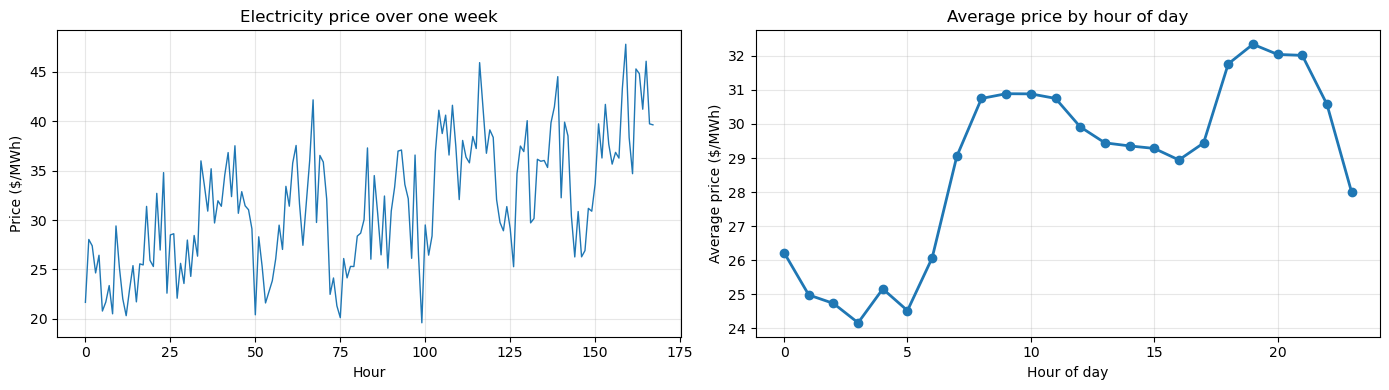

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# A week of prices to show the daily cycle
axes[0].plot(prices[:168], linewidth=1)
axes[0].set_title('Electricity price over one week')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Price ($/MWh)')

# Average price by hour of day
hourly_avg = pd.Series(prices).groupby(hours).mean()
axes[1].plot(hourly_avg.index, hourly_avg.values, 'o-', linewidth=2)
axes[1].set_title('Average price by hour of day')
axes[1].set_xlabel('Hour of day')
axes[1].set_ylabel('Average price ($/MWh)')
plt.tight_layout()
plt.show()

---

## Part 2: The Battery Trading Environment

The environment models a battery with a small number of discrete charge levels. At each hourly step the agent chooses one of three actions:

- **Hold**: do nothing.
- **Charge (buy)**: purchase one unit of energy at the current price and raise the battery level. The reward is the negative of the price, since buying costs money.
- **Discharge (sell)**: sell one unit of energy at the current price and lower the battery level. The reward is the price received.

Charging when full or discharging when empty is not possible and incurs a small penalty so the agent learns to avoid wasted actions. The goal is to accumulate profit over the episode by buying when prices are low and selling when they are high.

A rolling 24-hour average of the price is used as context throughout, so that the agents and the heuristic judge whether the current price is high or low relative to recent conditions rather than against a fixed value. This uses only past information and introduces no look-ahead.

In [4]:
N_SOC = 6   # number of discrete battery charge levels (0 = empty, 5 = full)

# Rolling 24-hour mean and standard deviation of price, using only past data
roll_mean = pd.Series(prices).rolling(24, min_periods=1).mean().values
roll_std = pd.Series(prices).rolling(24, min_periods=1).std().fillna(1).values
price_ratio = prices / roll_mean   # >1 means price is above its recent average

def environment_step(t, soc, action):
    """Apply an action at time t with battery level soc. Returns (reward, new_soc).
    Actions: 0 = hold, 1 = charge/buy, 2 = discharge/sell."""
    reward, new_soc = 0.0, soc
    if action == 1 and soc < N_SOC - 1:
        reward = -prices[t]
        new_soc = soc + 1
    elif action == 2 and soc > 0:
        reward = prices[t]
        new_soc = soc - 1
    elif (action == 1 and soc == N_SOC - 1) or (action == 2 and soc == 0):
        reward = -1.0   # small penalty for an impossible action
    return reward, new_soc

---

## Part 3: Baselines

Two baselines provide context for the learning agents. The random policy acts arbitrarily and shows what zero skill looks like. The rule-based heuristic encodes the obvious arbitrage logic directly, buying when the price is below its recent average and selling when it is above, with thresholds tuned for the best result. A strong heuristic is the honest benchmark to beat, since it represents what a sensible person would do without any learning.

In [5]:
def run_random(start, end, seed=0):
    rng = np.random.default_rng(seed)
    soc, profit = 0, 0.0
    for t in range(start, end - 1):
        a = rng.integers(3)
        if a == 1 and soc < N_SOC - 1:
            profit -= prices[t]; soc += 1
        elif a == 2 and soc > 0:
            profit += prices[t]; soc -= 1
    return profit

def run_rule(start, end, low=0.97, high=1.03):
    """Buy when price is below `low` times its recent average, sell when above `high`."""
    soc, profit = 0, 0.0
    for t in range(start, end - 1):
        if price_ratio[t] < low and soc < N_SOC - 1:
            profit -= prices[t]; soc += 1
        elif price_ratio[t] > high and soc > 0:
            profit += prices[t]; soc -= 1
    return profit

# Tune the heuristic thresholds on the training data, then lock them for the test set
best_rule_profit, best_lo, best_hi = -1e9, 0.97, 1.03
for lo in [0.93, 0.95, 0.97]:
    for hi in [1.03, 1.05, 1.07]:
        p = run_rule(0, SPLIT, lo, hi)
        if p > best_rule_profit:
            best_rule_profit, best_lo, best_hi = p, lo, hi
print(f"Best heuristic thresholds (tuned on train): low={best_lo}, high={best_hi}")

Best heuristic thresholds (tuned on train): low=0.97, high=1.03


---

## Part 4: Tabular Q-learning from Scratch

### 4.1 The Q-learning algorithm

Q-learning learns a value $Q(s, a)$ for taking action $a$ in state $s$, defined as the expected total future reward. The agent improves these estimates through experience using the Bellman update:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

Here $r$ is the immediate reward, $s'$ is the next state, $\alpha$ is the learning rate, and $\gamma$ is the discount factor that weights future rewards. The term in brackets is the temporal-difference error, the gap between the current estimate and a better one formed from the observed reward plus the best achievable value next. Actions are chosen by an epsilon-greedy policy, which takes the best known action most of the time but explores randomly with probability epsilon, decayed over training so the agent explores early and exploits later.

The state is discretized for the tabular method: the price relative to its recent average is placed into one of a few bins, and combined with the battery charge level.

In [6]:
ratio_bins = np.array([0.90, 0.97, 1.03, 1.10])

def discretize(t, soc):
    """Map continuous price ratio and battery level to a discrete state."""
    return (int(np.digitize(price_ratio[t], ratio_bins)), soc)

def train_q_learning(start, end, episodes=600, alpha=0.25, gamma=0.99):
    Q = {}
    def getQ(s, a):
        return Q.get((s, a), 0.0)
    rewards_per_episode = []
    for ep in range(episodes):
        epsilon = max(0.02, 1.0 - ep / (0.5 * episodes))
        soc, total = 0, 0.0
        for t in range(start, end - 1):
            s = discretize(t, soc)
            if np.random.rand() < epsilon:
                a = np.random.randint(3)
            else:
                a = max(range(3), key=lambda x: getQ(s, x))
            r, new_soc = environment_step(t, soc, a)
            s_next = discretize(t + 1, new_soc)
            best_next = max(getQ(s_next, x) for x in range(3))
            Q[(s, a)] = getQ(s, a) + alpha * (r + gamma * best_next - getQ(s, a))
            soc, total = new_soc, total + r
        rewards_per_episode.append(total)
    return Q, rewards_per_episode

def run_q_policy(Q, start, end):
    def getQ(s, a):
        return Q.get((s, a), 0.0)
    soc, profit = 0, 0.0
    for t in range(start, end - 1):
        s = discretize(t, soc)
        a = max(range(3), key=lambda x: getQ(s, x))
        if a == 1 and soc < N_SOC - 1:
            profit -= prices[t]; soc += 1
        elif a == 2 and soc > 0:
            profit += prices[t]; soc -= 1
    return profit

### 4.2 Training

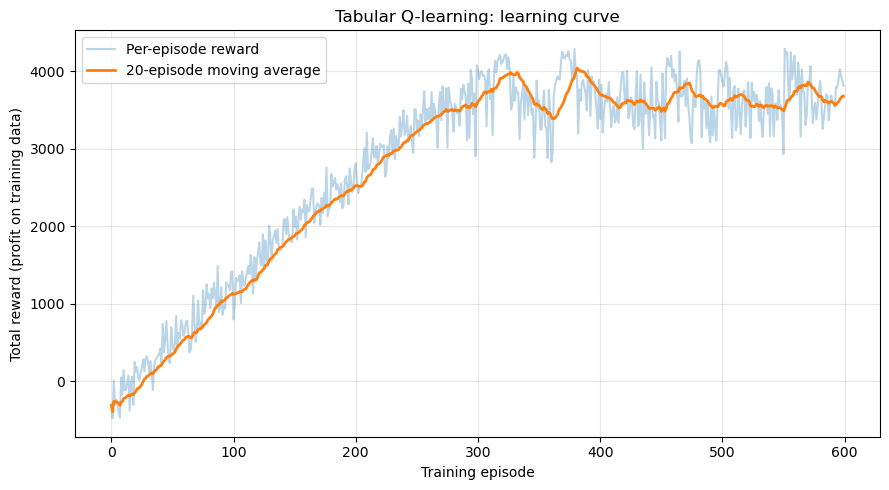

Reward improved from $-263 (first 10 episodes) to $3,789 (last 10 episodes).


In [7]:
np.random.seed(RANDOM_SEED)
Q_table, q_rewards = train_q_learning(0, SPLIT, episodes=600)

plt.figure(figsize=(9, 5))
# Smoothed learning curve
window = 20
smoothed = pd.Series(q_rewards).rolling(window, min_periods=1).mean()
plt.plot(q_rewards, alpha=0.3, label='Per-episode reward')
plt.plot(smoothed, linewidth=2, label=f'{window}-episode moving average')
plt.xlabel('Training episode')
plt.ylabel('Total reward (profit on training data)')
plt.title('Tabular Q-learning: learning curve')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Reward improved from ${np.mean(q_rewards[:10]):,.0f} (first 10 episodes) "
      f"to ${np.mean(q_rewards[-10:]):,.0f} (last 10 episodes).")

The reward climbs steeply and then plateaus, the signature of an agent that has discovered a good policy. Inspecting the learned policy confirms it buys when the price is low relative to its recent average and sells when it is high, which is the correct arbitrage logic.

### 4.3 Out-of-sample evaluation

In [8]:
q_test = run_q_policy(Q_table, SPLIT, len(prices))
rule_test = run_rule(SPLIT, len(prices), best_lo, best_hi)
random_test = np.mean([run_random(SPLIT, len(prices), s) for s in range(5)])

print("Out-of-sample profit on the held-out test period:")
print(f"  Random policy:        ${random_test:,.0f}")
print(f"  Tabular Q-learning:   ${q_test:,.0f}")
print(f"  Rule-based heuristic: ${rule_test:,.0f}")

Out-of-sample profit on the held-out test period:
  Random policy:        $-65
  Tabular Q-learning:   $1,617
  Rule-based heuristic: $1,778


The tabular agent decisively beats the random policy, confirming it has learned genuine arbitrage rather than trading noise. Against the tuned heuristic it is competitive but does not clearly win. This is an honest and informative result: for a problem this simple, with a one-dimensional price signal and clear buy-low-sell-high structure, a well-tuned heuristic directly encodes the optimal logic, and a tabular method that must discretize the state and learn each cell from limited data has little room to do better. The natural question is whether a richer, continuous representation can extract more, which motivates the deep Q-network.

### 5.1 Continuous state and network

The tabular method discards information by binning the price ratio into a few categories. A deep Q-network instead takes a continuous state and learns the action values with a neural network, so it can respond to fine gradations in price and to the time of day. The state used here has five continuous components: the price ratio, the price expressed as a standardized deviation from its recent average, the hour of day encoded as a sine and cosine pair, and the battery charge level as a fraction. The question is whether this richer representation lets the agent extract more than the discretized tabular method.

Two standard techniques stabilize training. **Experience replay** stores past transitions and trains on random batches of them, which breaks the correlation between consecutive samples. A **target network**, a periodically updated copy of the main network, provides stable targets for the Bellman update.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(RANDOM_SEED)

def state_vector(t, soc):
    """Continuous five-dimensional state for the DQN."""
    return np.array([
        price_ratio[t],
        (prices[t] - roll_mean[t]) / (roll_std[t] + 1e-6),
        np.sin(2 * np.pi * hours[t] / 24),
        np.cos(2 * np.pi * hours[t] / 24),
        soc / (N_SOC - 1),
    ], dtype=np.float32)

def build_network():
    model = keras.Sequential([
        layers.Input(shape=(5,)),
        layers.Dense(48, activation='relu'),
        layers.Dense(48, activation='relu'),
        layers.Dense(3),   # Q-value for each action
    ])
    model.compile(optimizer=keras.optimizers.Adam(0.002), loss='huber')
    return model

### 5.2 Training with experience replay

In [10]:
def train_dqn(start, end, episodes=45, gamma=0.99, batch_size=128):
    online = build_network()
    target = build_network()
    target.set_weights(online.get_weights())
    replay = deque(maxlen=8000)
    episode_rewards = []
    for ep in range(episodes):
        epsilon = max(0.05, 1.0 - ep / (0.7 * episodes))
        soc, total = 0, 0.0
        for t in range(start, end - 1):
            s = state_vector(t, soc)
            if np.random.rand() < epsilon:
                a = np.random.randint(3)
            else:
                a = int(np.argmax(online(s[None], training=False)[0]))
            r, new_soc = environment_step(t, soc, a)
            replay.append((s, a, r, state_vector(t + 1, new_soc)))
            soc, total = new_soc, total + r
            if len(replay) >= batch_size and (t - start) % 8 == 0:
                idx = np.random.choice(len(replay), batch_size, replace=False)
                bs = np.array([replay[i][0] for i in idx])
                ba = np.array([replay[i][1] for i in idx])
                br = np.array([replay[i][2] for i in idx], dtype=np.float32)
                bs2 = np.array([replay[i][3] for i in idx])
                next_q = target(bs2, training=False).numpy().max(axis=1)
                targets = online(bs, training=False).numpy()
                targets[np.arange(batch_size), ba] = br + gamma * next_q
                online.train_on_batch(bs, targets)
        if ep % 3 == 0:
            target.set_weights(online.get_weights())
        episode_rewards.append(total)
    target.set_weights(online.get_weights())
    return online, episode_rewards

def run_dqn_policy(model, start, end):
    soc, profit = 0, 0.0
    for t in range(start, end - 1):
        a = int(np.argmax(model(state_vector(t, soc)[None], training=False)[0]))
        if a == 1 and soc < N_SOC - 1:
            profit -= prices[t]; soc += 1
        elif a == 2 and soc > 0:
            profit += prices[t]; soc -= 1
    return profit

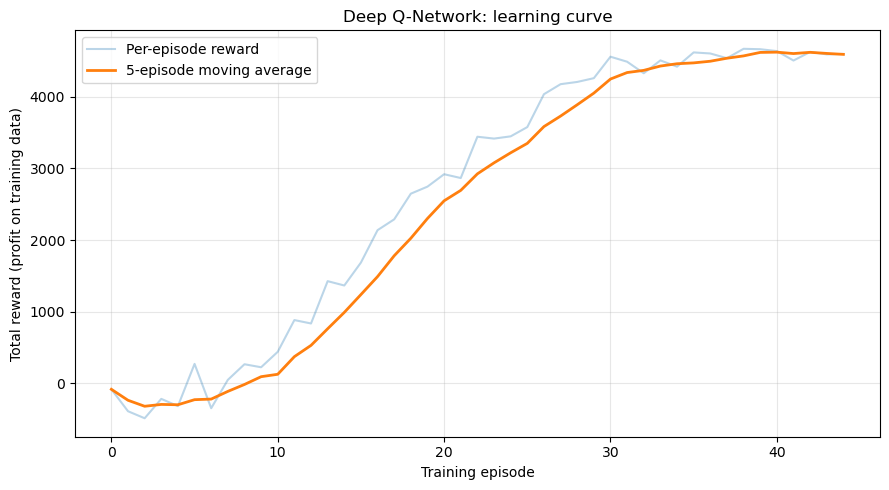

In [11]:
# Training the DQN takes a few minutes because of the neural-network updates.
dqn_model, dqn_rewards = train_dqn(0, SPLIT, episodes=45)

plt.figure(figsize=(9, 5))
smoothed = pd.Series(dqn_rewards).rolling(5, min_periods=1).mean()
plt.plot(dqn_rewards, alpha=0.3, label='Per-episode reward')
plt.plot(smoothed, linewidth=2, label='5-episode moving average')
plt.xlabel('Training episode')
plt.ylabel('Total reward (profit on training data)')
plt.title('Deep Q-Network: learning curve')
plt.legend()
plt.tight_layout()
plt.show()

### 5.3 Out-of-sample evaluation

In [12]:
dqn_test = run_dqn_policy(dqn_model, SPLIT, len(prices))

print("Out-of-sample profit on the held-out test period:")
print(f"  Random policy:        ${random_test:,.0f}")
print(f"  Rule-based heuristic: ${rule_test:,.0f}")
print(f"  Tabular Q-learning:   ${q_test:,.0f}")
print(f"  Deep Q-Network:       ${dqn_test:,.0f}")

Out-of-sample profit on the held-out test period:
  Random policy:        $-65
  Rule-based heuristic: $1,778
  Tabular Q-learning:   $1,617
  Deep Q-Network:       $1,845


---

## Part 6: Comparison and Reflection

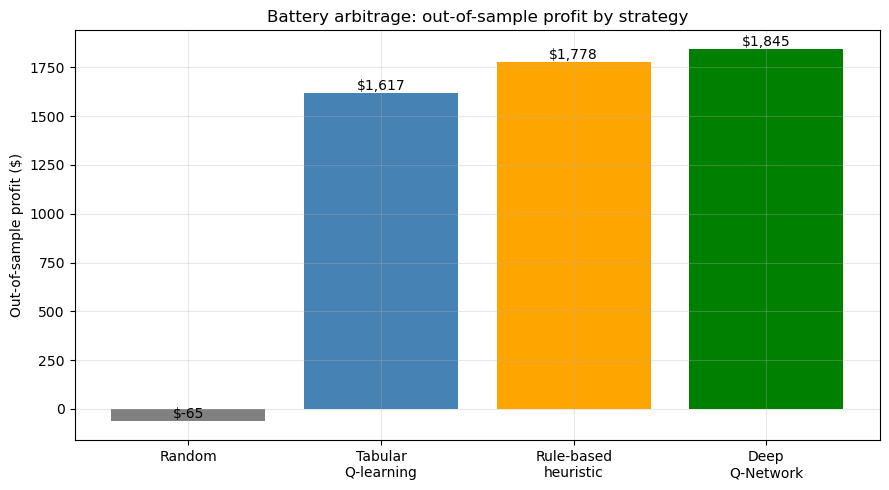

In [13]:
models = ['Random', 'Tabular\nQ-learning', 'Rule-based\nheuristic', 'Deep\nQ-Network']
profits = [random_test, q_test, rule_test, dqn_test]
colors = ['gray', 'steelblue', 'orange', 'green']

plt.figure(figsize=(9, 5))
bars = plt.bar(models, profits, color=colors)
plt.ylabel('Out-of-sample profit ($)')
plt.title('Battery arbitrage: out-of-sample profit by strategy')
for bar, p in zip(bars, profits):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'${p:,.0f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

### What this project demonstrates

- A battery arbitrage environment driven by a price signal derived from real electricity demand
- Tabular Q-learning implemented from scratch, including the Bellman update and an epsilon-greedy policy, benchmarked honestly against random and rule-based baselines
- A deep Q-network with a continuous state, experience replay, and a target network
- Strict out-of-sample evaluation, with all agents trained on earlier data and tested on a later, unseen period

### Key takeaways

1. The tabular agent learns genuine arbitrage. It beats a random policy by a wide margin and its learned policy follows the correct buy-low-sell-high logic, which confirms the Q-learning implementation is sound.
2. A tuned heuristic is a strong baseline. On a one-dimensional price signal with clear structure, the rule-based strategy directly encodes the optimal logic, and both the tabular agent and the deep Q-network are competitive with it without beating it. Recognizing that simple, well-tuned baselines are hard to beat on simple problems is an important part of honest evaluation.
3. A richer representation alone does not guarantee an improvement. The deep Q-network removes the discretization bottleneck of the tabular method, but on this problem that added capacity is not enough to overtake the heuristic, since the optimal policy is already simple. The value of deep reinforcement learning emerges on harder problems, where the optimal rule is not obvious and the state is high-dimensional.
4. The honest framing matters most. In trading problems, out-of-sample performance is what counts, and overfitting is a constant risk. The disciplined train-test separation and the comparison against strong baselines are what make the results trustworthy, and they matter more than any single headline number.
